# ReTest mini-demo
**Know which solar measurement is worth repeating.**

Team ReTest (Rishika Vats, Ayush Raj, Uswa Tariq), TeraOpenScience Idea Innovation Business Science Challenge 2026, #IdeaInnovationBusiness

This notebook is a working proof of concept for the ReTest proposal. It shows three things:

1. A **pvlib digital twin** of a two-week PV module comparison test.
2. How a **sensor fault can make a +2% module look like a +5% module**, pushing it over a +3% go/no-go threshold.
3. A **planner** that ranks follow-up checks by value of information and cost, then picks the cheapest one that settles the decision.

**Read this first.** The weather is simulated with pvlib's clear-sky model and a random cloud factor for Lubbock, TX. Costs and losses are relative units chosen for illustration, not prices. The planner here is the one-step value-of-information starting point; the Phase 1 project replaces simulated weather with public DOE PVDAQ data and tests stronger methods against it.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pvlib, retest_core as rc, benchmark as bm
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#2a2a28", "xtick.color": "#5c5b55",
                     "ytick.color": "#5c5b55", "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY = "#2a78d6", "#a8a79f"
print("pvlib", pvlib.__version__)

pvlib 0.16.1


## 1. The digital twin

Week 1: the lab measures the baseline module. Week 2: it measures the new module. Each week, measured power is divided by the power the twin expects from the **recorded** irradiance and temperature sensors. The ratio between the two weeks is the reported gain.

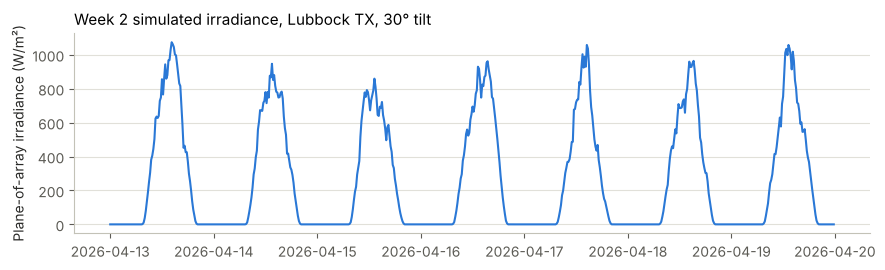

In [2]:
week1 = rc.simulate_weather("2026-04-06", seed=1)
week2 = rc.simulate_weather("2026-04-13", seed=2)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(week2.index, week2["poa"], color=BLUE, lw=1.5)
ax.set_ylabel("Plane-of-array irradiance (W/m²)")
ax.set_title("Week 2 simulated irradiance, Lubbock TX, 30° tilt", loc="left", fontsize=11)
ax.grid(axis="y", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 2. The problem: one result, several explanations

The new module's **true** gain is +2.0%, below the +3% threshold. But the week 2 irradiance sensor has drifted and reads 3% low. The twin shows what the lab would see.

In [3]:
TRUTH = (0.02, -0.03, 0.0)   # true gain, irradiance drift, temperature bias
observed = rc.apparent_gain(week1, week2, *TRUTH)
print(f"True gain:      {TRUTH[0]:+.1%}")
print(f"Reported gain:  {observed:+.1%}   (threshold {rc.THRESHOLD:+.0%})")
print("Taken at face value, the module would advance. That decision is wrong.")

True gain:      +2.0%
Reported gain:  +5.2%   (threshold +3%)
Taken at face value, the module would advance. That decision is wrong.


The twin is run for **171 explanations**: every combination of true gain (-1% to +8%), irradiance drift (0, -1.5%, -3%) and temperature-sensor bias (-3, 0, +3 °C). Below are the explanations that best fit the reported +5.2%. They disagree about the decision.

In [4]:
h = rc.build_hypotheses(week1, week2)
w0 = rc.update(h["prior"].values, h, "original", observed)
top = h.assign(posterior=w0).sort_values("posterior", ascending=False).head(6)
show = pd.DataFrame({
    "true gain": top["gain"].map("{:+.1%}".format),
    "irradiance drift": top["drift"].map("{:+.1%}".format),
    "temp bias (°C)": top["bias"].map("{:+.0f}".format),
    "twin predicts": top["apparent"].map("{:+.1%}".format),
    "probability": top["posterior"].map("{:.0%}".format),
    "decision if true": np.where(top["gain"] >= rc.THRESHOLD - 1e-9, "advance", "reject")})
print(f"Probability the module truly clears +3%: {rc.p_pass(w0, h):.0%}")
show.reset_index(drop=True)

Probability the module truly clears +3%: 85%


,true gain,irradiance drift,temp bias (°C),twin predicts,probability,decision if true
0,+5.0%,+0.0%,+0,+5.0%,26%,advance
1,+5.5%,+0.0%,+0,+5.5%,19%,advance
2,+4.5%,+0.0%,+0,+4.5%,7%,advance
3,+2.0%,-3.0%,+0,+5.2%,6%,reject
4,+3.5%,-1.5%,+0,+5.1%,6%,advance
5,+4.0%,+0.0%,+3,+5.2%,3%,advance


## 3. ReTest picks the next check

Three follow-up checks are available. Each is scored by its cost plus the expected cost of a wrong decision after seeing its result. A wrong advance or wrong rejection is set to 20 units, and a full rerun costs 8 times a sensor check. Both are adjustable assumptions.

In [5]:
rng = np.random.default_rng(7)
advance, spent, done, w_final, steps = rc.retest_policy(h, observed, TRUTH, rng)
for i, (ranking, pp) in enumerate(steps, 1):
    print(f"Step {i}: probability of clearing +3% = {pp:.0%}")
    print(ranking.round(2).to_string(index=False), "\n")
print("Checks run:", done)
print(f"Test cost: {spent:.0f} units   Final probability of clearing +3%: {rc.p_pass(w_final, h):.0%}")
print("Decision:", "ADVANCE" if advance else "DO NOT ADVANCE", "  (correct)" if advance == (TRUTH[0] >= rc.THRESHOLD) else "  (wrong)")

Step 1: probability of clearing +3% = 85%
                        action  cost  expected_loss  total
          Reference-cell check   1.0           0.56   1.56
                    Decide now   0.0           2.90   2.90
Synchronized temperature check   1.0           3.00   4.00
                    Full rerun   8.0           0.85   8.85 

Step 2: probability of clearing +3% = 10%
                        action  cost  expected_loss  total
Synchronized temperature check   1.0           0.63   1.63
                    Decide now   0.0           2.07   2.07
                    Full rerun   8.0           1.51   9.51 

Step 3: probability of clearing +3% = 2%
    action  cost  expected_loss  total
Decide now   0.0           0.38   0.38
Full rerun   8.0           0.38   8.38 

Checks run: ['Reference-cell check', 'Synchronized temperature check']
Test cost: 2 units   Final probability of clearing +3%: 2%
Decision: DO NOT ADVANCE   (correct)


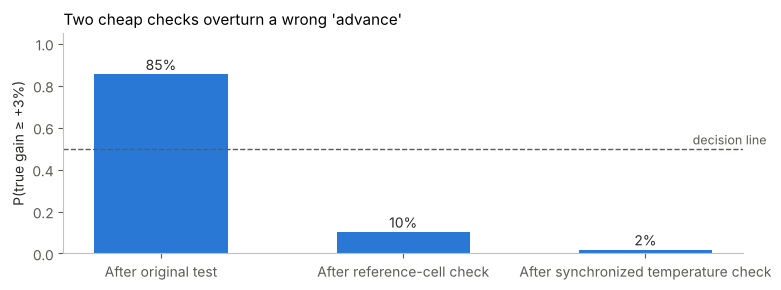

In [6]:
labels = ["After original test"] + [f"After {d.lower()}" for d in done]
probs = [pp for _, pp in steps]
if len(probs) < len(labels): probs.append(rc.p_pass(w_final, h))
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.bar(labels, probs, color=BLUE, width=0.55)
ax.axhline(0.5, color="#5c5b55", lw=1, ls="--"); ax.text(len(labels) - 0.5, 0.52, "decision line", ha="right", color="#5c5b55", fontsize=9)
for b, p in zip(bars, probs): ax.text(b.get_x() + b.get_width() / 2, p + 0.02, f"{p:.0%}", ha="center", color="#2a2a28")
ax.set_ylim(0, 1.05); ax.set_ylabel("P(true gain ≥ +3%)")
ax.set_title("Two cheap checks overturn a wrong 'advance'", loc="left", fontsize=11)
plt.tight_layout(); plt.savefig("fig_decision_path.png", dpi=160); plt.show()

The reference-cell check finds the drift. A temperature check then rules out the remaining alternative. Total cost is 2 units, against 8 for a full rerun. The full rerun was never the best next step.

## 4. Mini-benchmark: 500 borderline cases

Cases are drawn from the same prior and kept only when the reported gain falls between +2% and +6%, which is the borderline zone where ReTest would be used. Ground truth is known because the faults are injected. Each policy sees the same cases.

In [7]:
res = bm.run_benchmark(h, n_cases=500, seed=42)
table = res.assign(wrong_decision_rate=res["wrong_decision_rate"].map("{:.1%}".format),
                   avg_test_cost=res["avg_test_cost"].map("{:.2f}".format),
                   avg_total_cost=res["avg_total_cost"].map("{:.2f}".format))
table

,cases,wrong_decision_rate,avg_test_cost,avg_total_cost
policy,,,,
Trust the measurement,500,22.4%,0.00,4.48
Fixed checklist,500,8.0%,2.00,3.60
Always full rerun,500,7.8%,8.00,9.56
ReTest planner,500,9.6%,1.04,2.96


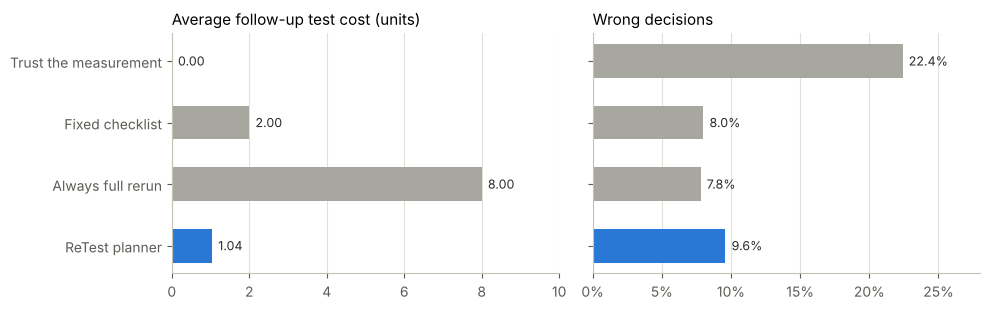

In [8]:
order = list(res.index)
colors = [BLUE if p == "ReTest planner" else GRAY for p in order]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, title, fmt in [(axes[0], "avg_test_cost", "Average follow-up test cost (units)", "{:.2f}"),
                            (axes[1], "wrong_decision_rate", "Wrong decisions", "{:.1%}")]:
    vals = res[col].values
    bars = ax.barh(order, vals, color=colors, height=0.55)
    ax.invert_yaxis(); ax.set_title(title, loc="left", fontsize=11)
    for b, v in zip(bars, vals): ax.text(v + vals.max() * 0.02, b.get_y() + b.get_height() / 2, fmt.format(v), va="center", fontsize=9, color="#2a2a28")
    ax.set_xlim(0, vals.max() * 1.25); ax.grid(axis="x", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
axes[1].set_yticklabels([]); axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
plt.tight_layout(); plt.savefig("fig_benchmark.png", dpi=160); plt.show()

### What this shows, honestly

* **Trusting the measurement** is wrong in about 1 of 5 borderline cases.
* **ReTest** cuts the follow-up test spend roughly in half compared with always running both sensor checks, and it is far cheaper than always repeating the full test.
* **The trade-off is real.** In this run ReTest made slightly more wrong decisions than the fixed checklist (9.6% vs 8.0%). It had the lowest total cost under these assumptions, but a lab that weights errors more heavily would set a higher loss, and the planner would then buy more checks. Making that trade-off explicit is the point.

### Limits of this demo

* Simulated weather, not measured data. Phase 1 replays public DOE PVDAQ systems.
* The prior used to generate cases is the same one the planner assumes. Phase 1 tests deliberately wrong priors and correlated faults.
* The planner is one-step value of information. Phase 1 benchmarks it against goal-driven and risk-aware experimental design methods.
* Costs are relative units. Real costs come from customer interviews.